# 03 Explore: what goes with a high rating?

- **Reads:** data/processed/movies.parquet
- **Writes:** nothing
- **Run after:** 02_clean_join

What I found: old classics rate higher on average (partly survivorship bias), Horror is the lowest-rated genre and Biography/Documentary the highest, and the most consistent directors aren't the famous ones.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

MOVIES = "../data/processed/movies.parquet"

movies = pd.read_parquet(MOVIES)
print(movies.shape)
movies[["title", "year", "runtime", "rating", "votes", "director"]].head()

(49453, 34)


,title,year,runtime,rating,votes,director
0,The Shawshank Redemption,1994,142,9.3,3262239,Frank Darabont
1,The Dark Knight,2008,152,9.1,3248055,Christopher Nolan
2,Inception,2010,148,8.8,2887178,Christopher Nolan
3,Fight Club,1999,139,8.8,2681152,David Fincher
4,Interstellar,2014,169,8.7,2630975,Christopher Nolan


In [2]:
movies["decade"] = (movies["year"] // 10) * 10
movies[["title", "year", "decade"]].sample(5, random_state=1)

,title,year,decade
40999,Green and Gold,2025,2020
677,A Bug's Life,1998,1990
5666,Raazi,2018,2010
37452,"Where Are You Going, Habibi?",2015,2010
21853,Simon Says,2006,2000


In [3]:
movies["rating"].describe().round(2)

count    49453.00
mean         6.23
std          1.17
min          1.00
25%          5.60
50%          6.40
75%          7.10
max         10.00
Name: rating, dtype: float64

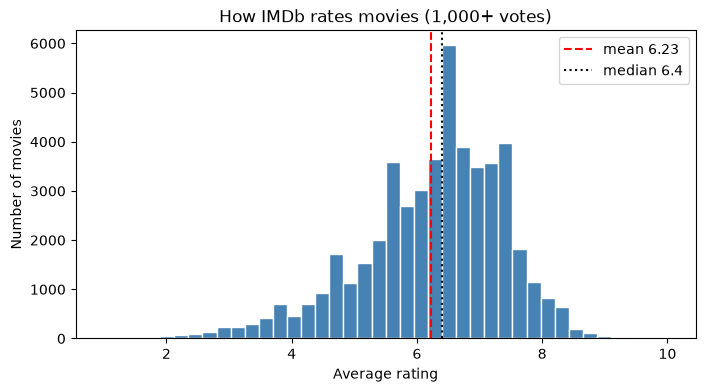

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(movies["rating"], bins=40, color="steelblue", edgecolor="white")

mean = movies["rating"].mean()
median = movies["rating"].median()
ax.axvline(mean, color="red", linestyle="--", label=f"mean {mean:.2f}")
ax.axvline(median, color="black", linestyle=":", label=f"median {median:.1f}")

ax.set(title="How IMDb rates movies (1,000+ votes)",
       xlabel="Average rating", ylabel="Number of movies")
ax.legend()
plt.show()

## 2. Ratings by decade

In [5]:
by_decade = (movies.groupby("decade")["rating"]
             .agg(["count", "mean", "median"])
             .round(2))
by_decade

,count,mean,median
decade,,,
1900,1,6.00,6.0
1910,58,6.66,6.7
1920,245,7.02,7.1
1930,822,6.79,6.8
1940,1146,6.80,6.8
1950,1631,6.65,6.8
1960,2042,6.61,6.7
1970,2620,6.47,6.6
1980,3379,6.27,6.4


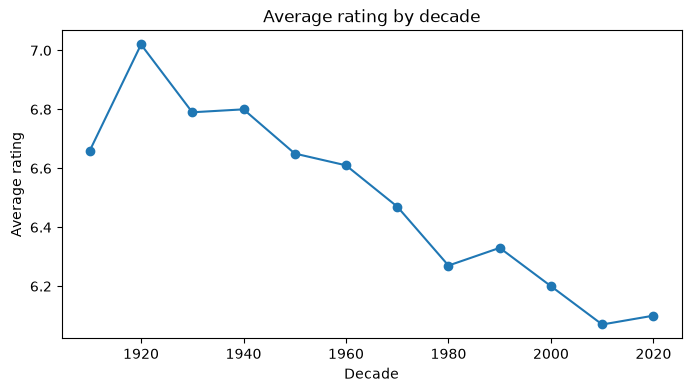

In [6]:
MIN_MOVIES = 50
decades = by_decade[by_decade["count"] >= MIN_MOVIES]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(decades.index, decades["mean"], marker="o")
ax.set(title="Average rating by decade",
       xlabel="Decade", ylabel="Average rating")
plt.show()

## 3. Ratings by genre

In [7]:
by_genre = (movies.explode("genre_list")
            .groupby("genre_list")["rating"]
            .agg(["count", "mean"])
            .round(2)
            .sort_values("mean"))
by_genre

,count,mean
genre_list,,
Horror,6693,5.25
Sci-Fi,2394,5.43
Thriller,7592,5.82
Action,8978,5.93
Fantasy,2675,5.94
Mystery,4215,5.98
Adventure,5352,6.11
Comedy,16463,6.15
Family,2074,6.23


22 genres with 100 + movies


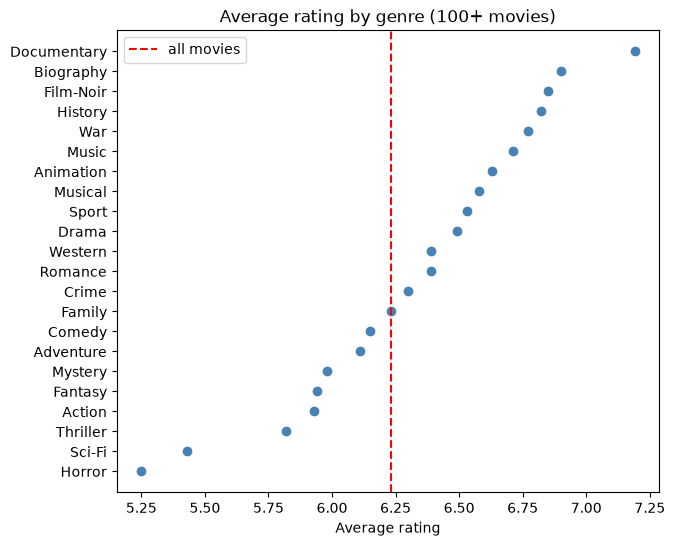

In [8]:
MIN_GENRE = 100
common = by_genre[by_genre["count"] >= MIN_GENRE]
print(len(common), "genres with", MIN_GENRE, "+ movies")

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(common["mean"], common.index, color="steelblue")
ax.axvline(movies["rating"].mean(), color="red", linestyle="--",
           label="all movies")
ax.set(title="Average rating by genre (100+ movies)",
       xlabel="Average rating")
ax.legend()
plt.show()

## 4. Runtime vs rating

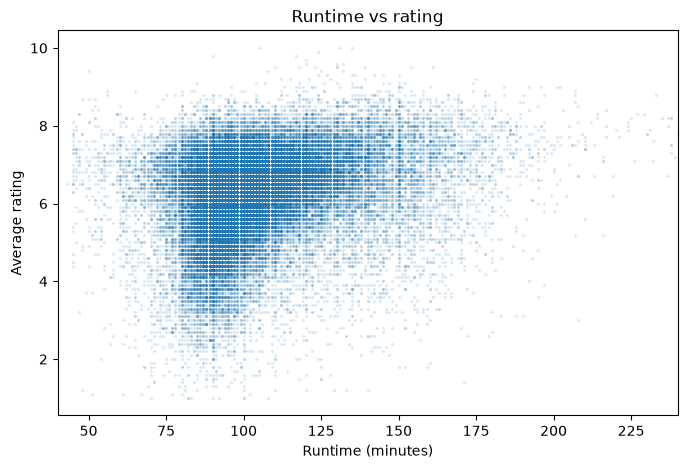

In [9]:
timed = movies.dropna(subset=["runtime"])

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(timed["runtime"], timed["rating"], s=2, alpha=0.1)
ax.set_xlim(40, 240)
ax.set(title="Runtime vs rating",
       xlabel="Runtime (minutes)", ylabel="Average rating")
plt.show()

In [10]:
bins = [0, 80, 90, 100, 110, 120, 135, 150, 180, 1000]
movies["runtime_band"] = pd.cut(movies["runtime"], bins=bins)

movies.groupby("runtime_band", observed=True)["rating"].agg(["count", "mean"]).round(2)

,count,mean
runtime_band,,
"(0, 80]",3115,5.98
"(80, 90]",8864,5.77
"(90, 100]",12808,6.01
"(100, 110]",9320,6.34
"(110, 120]",5703,6.56
"(120, 135]",4776,6.69
"(135, 150]",2561,6.74
"(150, 180]",1904,6.74
"(180, 1000]",344,7.28


In [11]:
round(movies["runtime"].corr(movies["rating"]), 2)

np.float64(0.26)

## 5. Votes vs rating

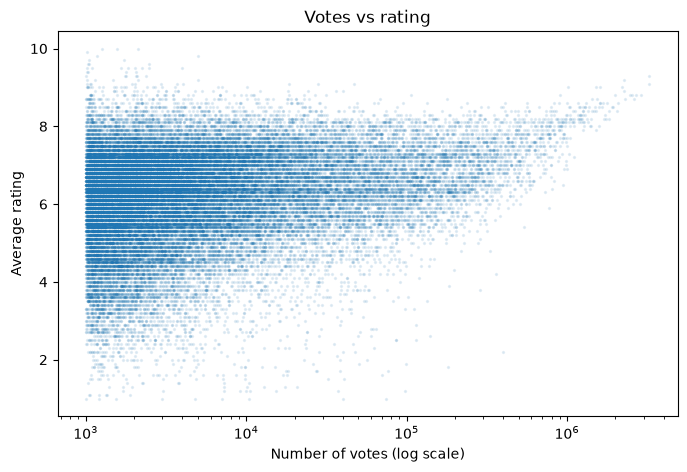

In [12]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(movies["votes"], movies["rating"], s=2, alpha=0.1)
ax.set_xscale("log")
ax.set(title="Votes vs rating",
       xlabel="Number of votes (log scale)", ylabel="Average rating")
plt.show()

In [13]:
print("votes:    ", round(movies["votes"].corr(movies["rating"]), 2))
print("log votes:", round(np.log10(movies["votes"]).corr(movies["rating"]), 2))

votes:     0.18
log votes: 0.23


In [14]:
vote_bins = [1_000, 2_000, 5_000, 10_000, 50_000, 100_000, 500_000, 5_000_000]
movies["vote_band"] = pd.cut(movies["votes"], bins=vote_bins, right=False)

movies.groupby("vote_band", observed=True)["rating"].agg(["count", "mean"]).round(2)

,count,mean
vote_band,,
"[1000, 2000)",15970,5.98
"[2000, 5000)",14223,6.16
"[5000, 10000)",6581,6.33
"[10000, 50000)",7991,6.45
"[50000, 100000)",1923,6.55
"[100000, 500000)",2373,6.86
"[500000, 5000000)",392,7.76


## 6. Most consistent directors

In [15]:
directors = (movies.groupby(["director_id", "director"])["rating"]
             .agg(films="count", avg="mean", spread="std")
             .reset_index())
print(len(directors), "directors")
print("Names shared by 2+ people:", directors["director"].duplicated().sum())
directors["films"].value_counts().sort_index().head(6)

20522 directors
Names shared by 2+ people: 51


films
1    12348
2     3282
3     1606
4      957
5      536
6      399
Name: count, dtype: int64

In [16]:
MIN_FILMS = 8
regulars = directors[directors["films"] >= MIN_FILMS]
print(len(regulars), "directors with", MIN_FILMS, "+ films")

regulars.sort_values("spread").head(10).round(2)

1111 directors with 8 + films


,director_id,director,films,avg,spread
9800,nm10201503,Park Jun-soo,8,8.36,0.12
1777,nm0102908,Robert N. Bradbury,10,5.25,0.16
8029,nm0782430,Ulrich Seidl,10,6.81,0.19
260,nm0000923,Busby Berkeley,9,6.70,0.19
460,nm0001789,Andrei Tarkovsky,8,7.86,0.20
3917,nm0336695,James Gray,8,6.62,0.21
8031,nm0782597,Lewis Seiler,11,6.60,0.21
2211,nm0151653,Cheh Chang,12,6.99,0.21
10665,nm1167622,Tsutomu Shibayama,11,7.28,0.21
6624,nm0621540,Mikio Naruse,8,7.70,0.22


In [17]:
good = regulars[regulars["avg"] >= 7.0]
good.sort_values("spread").head(10).round(2)

,director_id,director,films,avg,spread
9800,nm10201503,Park Jun-soo,8,8.36,0.12
460,nm0001789,Andrei Tarkovsky,8,7.86,0.20
10665,nm1167622,Tsutomu Shibayama,11,7.28,0.21
6624,nm0621540,Mikio Naruse,8,7.70,0.22
4780,nm0422605,Zhangke Jia,10,7.08,0.24
6256,nm0579954,Jiří Menzel,8,7.44,0.27
7873,nm0767110,Claude Sautet,11,7.20,0.28
6880,nm0649097,Max Ophüls,9,7.40,0.28
2339,nm0163229,René Clair,12,7.02,0.29
9405,nm0946638,Kimiyoshi Yasuda,8,7.04,0.30


In [18]:
regulars.sort_values("films", ascending=False).head(5).round(2)

,director_id,director,films,avg,spread
497,nm0002031,Michael Curtiz,59,6.84,0.57
6,nm0000033,Alfred Hitchcock,53,6.87,0.91
24,nm0000095,Woody Allen,51,6.93,0.53
120,nm0000406,John Ford,50,7.00,0.54
9104,nm0909825,Raoul Walsh,46,6.71,0.57


In [19]:
regulars.sort_values("avg", ascending=False).head(15).round(2)

,director_id,director,films,avg,spread
9800,nm10201503,Park Jun-soo,8,8.36,0.12
6745,nm0634240,Christopher Nolan,13,8.18,0.59
11954,nm1417038,Haruo Sotozaki,8,8.18,0.45
5914,nm0539034,Sibi Malayil,10,8.07,0.75
5197,nm0462030,Masaki Kobayashi,9,8.04,0.63
1698,nm0094083,Sergey Bondarchuk,8,7.95,0.33
818,nm0006249,Satyajit Ray,28,7.93,0.41
6391,nm0594503,Hayao Miyazaki,12,7.92,0.36
460,nm0001789,Andrei Tarkovsky,8,7.86,0.20
3127,nm0251027,Ertem Eğilmez,21,7.85,0.81


## Findings

1. Old classic movies are rated higher on average than today's, but that is also because there are many more recent movies than old ones (only the old films people still watch get 1,000+ votes).
2. The lowest-average genre is Horror and the highest are Biography/Documentary movies, with Romance sitting comfortably in the middle.
3. Surprised to see no familiar names among the most consistent directors, even though famous directors have high averages: e.g. Nolan, with an average rating of 8.18, was not in the top 5 consistent directors.